<a href="https://colab.research.google.com/github/kelvinpham220704/SKYT/blob/main/AI_KhuNhieuRDM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os
import random
import time
import json

import numpy as np
import scipy.io as sio
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị huấn luyện:", DEVICE)

# Sửa đường dẫn này cho đúng với tên folder trên Google Drive của bạn
DATA_ROOT = Path(
    "/content/drive/MyDrive/ISAC_Dataset_RDM_v2"
)

INPUT_DIR = DATA_ROOT / "inputs"
TARGET_DIR = DATA_ROOT / "targets"
LABEL_DIR = DATA_ROOT / "labels"

RUN_DIR = DATA_ROOT / "training_results"
RUN_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 16
EPOCHS = 60
LEARNING_RATE = 1e-3
PATIENCE = 10
NUM_WORKERS = 2

print("Dataset tồn tại:", DATA_ROOT.exists())
print("Inputs tồn tại:", INPUT_DIR.exists())
print("Targets tồn tại:", TARGET_DIR.exists())
print("Nơi lưu model:", RUN_DIR)

Thiết bị huấn luyện: cuda
Dataset tồn tại: True
Inputs tồn tại: True
Targets tồn tại: True
Nơi lưu model: /content/drive/MyDrive/ISAC_Dataset_RDM_v2/training_results


In [3]:
def load_rdm(path, candidate_names):
    data = sio.loadmat(path)

    for key in candidate_names:
        if key in data:
            arr = np.squeeze(np.asarray(data[key]))

            if arr.ndim == 2:
                return arr.astype(np.float32)

    keys = [k for k in data.keys() if not k.startswith("__")]

    raise ValueError(
        f"Không tìm thấy ma trận RDM trong {path.name}. "
        f"Các biến hiện có: {keys}"
    )


if not INPUT_DIR.exists() or not TARGET_DIR.exists():
    raise FileNotFoundError(
        f"Không tìm thấy inputs/targets tại {DATA_ROOT}. "
        "Hãy kiểm tra lại đường dẫn Drive."
    )

input_files = {p.name: p for p in INPUT_DIR.glob("*.mat")}
target_files = {p.name: p for p in TARGET_DIR.glob("*.mat")}

common_names = sorted(set(input_files) & set(target_files))

print("Số file input:", len(input_files))
print("Số file target:", len(target_files))
print("Số cặp khớp tên:", len(common_names))

print("Một số file mẫu:", common_names[:5])

if len(common_names) < 10:
    raise RuntimeError(
        "Có ít hơn 10 cặp file. Hãy kiểm tra cấu trúc dataset "
        "và bảo đảm tên file input/target giống nhau."
    )

Số file input: 500
Số file target: 500
Số cặp khớp tên: 500
Một số file mẫu: ['sample_00001.mat', 'sample_00002.mat', 'sample_00003.mat', 'sample_00004.mat', 'sample_00005.mat']


In [4]:
X_list = []
Y_list = []
valid_names = []
bad_samples = []

for name in common_names:
    try:
        x = load_rdm(
            input_files[name],
            ["rdmInput_norm", "rdmInput", "input", "noisy"]
        )

        y = load_rdm(
            target_files[name],
            ["rdmClean_norm", "rdmClean", "target", "clean"]
        )

        if x.shape != y.shape:
            raise ValueError(
                f"Kích thước khác nhau: {x.shape} và {y.shape}"
            )

        if not np.isfinite(x).all():
            raise ValueError("Input có NaN hoặc Inf")

        if not np.isfinite(y).all():
            raise ValueError("Target có NaN hoặc Inf")

        X_list.append(x)
        Y_list.append(y)
        valid_names.append(name)

    except Exception as e:
        bad_samples.append((name, str(e)))

print("Số mẫu hợp lệ:", len(X_list))
print("Số mẫu bị bỏ:", len(bad_samples))

if bad_samples:
    print("Ví dụ lỗi:", bad_samples[:5])

if len(X_list) < 10:
    raise RuntimeError("Không đủ mẫu hợp lệ để tiếp tục.")

# Shape: [N, 1, H, W] cho Conv2D của PyTorch
X = np.asarray(X_list, dtype=np.float32)[:, None, :, :]
Y = np.asarray(Y_list, dtype=np.float32)[:, None, :, :]

print("X:", X.shape)
print("Y:", Y.shape)

print("Input min/max:", X.min(), X.max())
print("Target min/max:", Y.min(), Y.max())

print("Input mean/std:", X.mean(), X.std())
print("Target mean/std:", Y.mean(), Y.std())

print("Input có NaN:", np.isnan(X).any())
print("Target có NaN:", np.isnan(Y).any())

if X.min() < -1e-4 or X.max() > 1.0001:
    print("CẢNH BÁO: Input nằm ngoài [0,1].")

if Y.min() < -1e-4 or Y.max() > 1.0001:
    print("CẢNH BÁO: Target nằm ngoài [0,1].")

Số mẫu hợp lệ: 500
Số mẫu bị bỏ: 0
X: (500, 1, 128, 128)
Y: (500, 1, 128, 128)
Input min/max: 0.0 1.0
Target min/max: 0.0 1.0
Input mean/std: 0.08617447 0.14210673
Target mean/std: 0.07456753 0.13776417
Input có NaN: False
Target có NaN: False


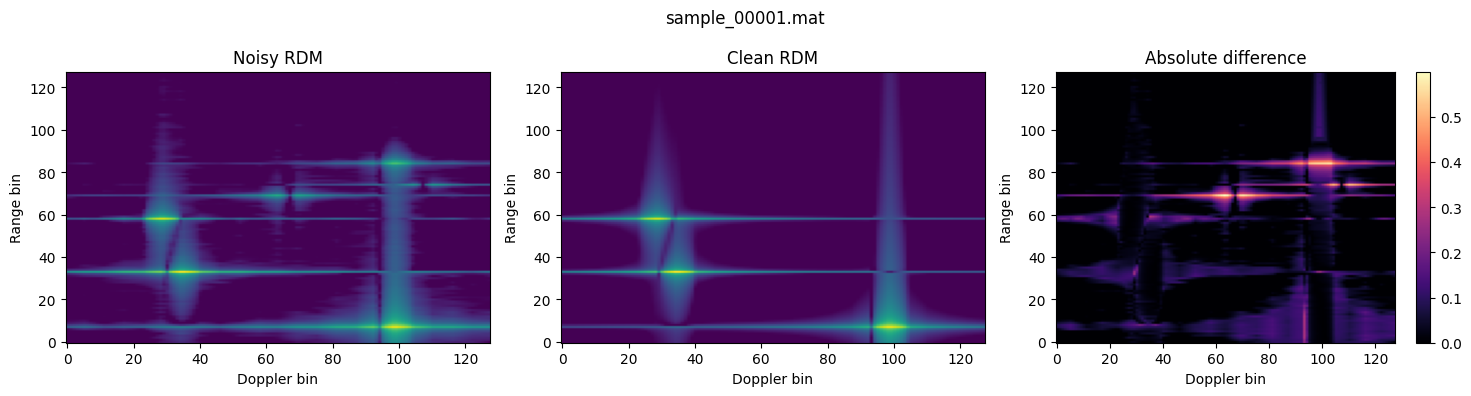

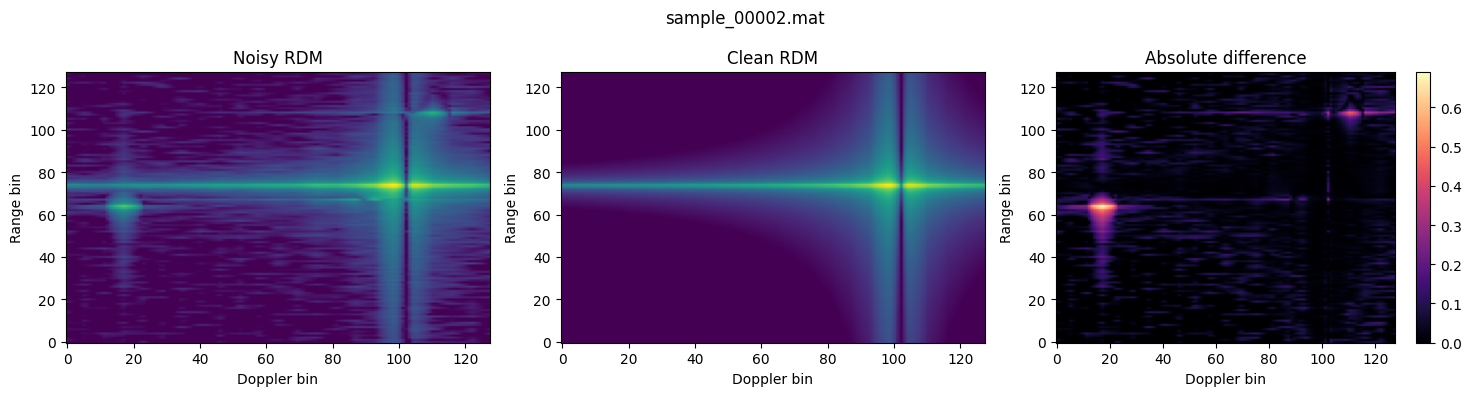

In [5]:
def show_dataset_sample(index=0):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].imshow(
        X[index, 0],
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )
    axes[0].set_title("Noisy RDM")

    axes[1].imshow(
        Y[index, 0],
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Clean RDM")

    diff = np.abs(X[index, 0] - Y[index, 0])

    im = axes[2].imshow(
        diff,
        origin="lower",
        aspect="auto",
        cmap="magma"
    )
    axes[2].set_title("Absolute difference")

    for ax in axes:
        ax.set_xlabel("Doppler bin")
        ax.set_ylabel("Range bin")

    fig.colorbar(im, ax=axes[2])
    plt.suptitle(valid_names[index])
    plt.tight_layout()
    plt.show()


show_dataset_sample(0)

if len(X) > 1:
    show_dataset_sample(1)

In [6]:
class RDMData(Dataset):
    def __init__(self, x, y):
        self.x = torch.from_numpy(x)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]


dataset = RDMData(X, Y)

n = len(dataset)
n_train = int(0.70 * n)
n_val = int(0.15 * n)
n_test = n - n_train - n_val

train_ds, val_ds, test_ds = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))

Train: 350
Validation: 75
Test: 75


In [7]:
def get_groups(channels):
    for g in [8, 4, 2, 1]:
        if channels % g == 0:
            return g
    return 1


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.GroupNorm(get_groups(out_channels), out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.GroupNorm(get_groups(out_channels), out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNetRDM(nn.Module):
    def __init__(self, base=32):
        super().__init__()

        self.enc1 = ConvBlock(1, base)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ConvBlock(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = ConvBlock(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, 2)
        self.dec3 = ConvBlock(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, 2)
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.dec1 = ConvBlock(base * 2, base)

        self.out = nn.Conv2d(base, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return torch.sigmoid(self.out(d1))


model = UNetRDM(base=32).to(DEVICE)

print(
    "Số tham số:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

# Kiểm tra kích thước đầu ra trước khi train
test_tensor = torch.zeros(
    2, 1, X.shape[-2], X.shape[-1], device=DEVICE
)

print("Output shape:", model(test_tensor).shape)

Số tham số: 1926433
Output shape: torch.Size([2, 1, 128, 128])


In [8]:
criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "learning_rate": []
}

BEST_MODEL_PATH = RUN_DIR / "unet_rdm_best.pt"


def run_epoch(loader, training):
    model.train(training)

    total_loss = 0.0
    total_samples = 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            prediction = model(xb)
            loss = criterion(prediction, yb)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            total_samples += xb.size(0)

    return total_loss / max(total_samples, 1)


start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["learning_rate"].append(current_lr)

    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"Train={train_loss:.6f} | "
        f"Val={val_loss:.6f} | "
        f"LR={current_lr:.2e}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "input_shape": list(X.shape[1:]),
                "seed": SEED
            },
            BEST_MODEL_PATH
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break


elapsed_seconds = time.time() - start_time

pd.DataFrame(history).to_csv(
    RUN_DIR / "training_history.csv",
    index_label="epoch"
)

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print(f"Training time: {elapsed_seconds / 60:.2f} minutes")
print("Model saved:", BEST_MODEL_PATH)

Epoch 001/60 | Train=0.042756 | Val=0.012324 | LR=1.00e-03
Epoch 002/60 | Train=0.009456 | Val=0.007960 | LR=1.00e-03
Epoch 003/60 | Train=0.006397 | Val=0.005845 | LR=1.00e-03
Epoch 004/60 | Train=0.004910 | Val=0.004861 | LR=1.00e-03
Epoch 005/60 | Train=0.004074 | Val=0.003871 | LR=1.00e-03
Epoch 006/60 | Train=0.003497 | Val=0.003483 | LR=1.00e-03
Epoch 007/60 | Train=0.003190 | Val=0.003256 | LR=1.00e-03
Epoch 008/60 | Train=0.002768 | Val=0.002871 | LR=1.00e-03
Epoch 009/60 | Train=0.002604 | Val=0.002666 | LR=1.00e-03
Epoch 010/60 | Train=0.002484 | Val=0.002589 | LR=1.00e-03
Epoch 011/60 | Train=0.002292 | Val=0.002581 | LR=1.00e-03
Epoch 012/60 | Train=0.002167 | Val=0.002201 | LR=1.00e-03
Epoch 013/60 | Train=0.001862 | Val=0.002302 | LR=1.00e-03
Epoch 014/60 | Train=0.002053 | Val=0.001965 | LR=1.00e-03
Epoch 015/60 | Train=0.001775 | Val=0.001967 | LR=1.00e-03
Epoch 016/60 | Train=0.001624 | Val=0.001700 | LR=1.00e-03
Epoch 017/60 | Train=0.001470 | Val=0.001770 | LR=1.00e-

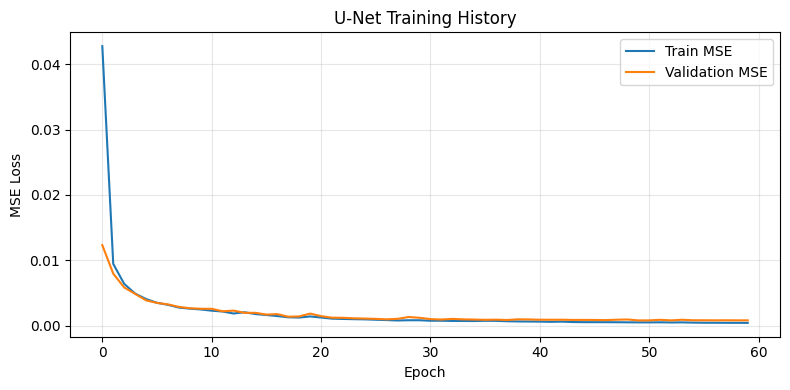

In [9]:
plt.figure(figsize=(8, 4))

plt.plot(history["train_loss"], label="Train MSE")
plt.plot(history["val_loss"], label="Validation MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("U-Net Training History")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

noisy_results = []
prediction_results = []
clean_results = []

with torch.no_grad():
    for xb, yb in test_loader:
        prediction = model(xb.to(DEVICE)).cpu().numpy()

        noisy_results.append(xb.numpy())
        prediction_results.append(prediction)
        clean_results.append(yb.numpy())

noisy_test = np.concatenate(noisy_results, axis=0)
pred_test = np.concatenate(prediction_results, axis=0)
clean_test = np.concatenate(clean_results, axis=0)


def calculate_nmse(prediction, reference, eps=1e-12):
    axes = tuple(range(1, prediction.ndim))

    numerator = np.sum(
        (prediction - reference) ** 2,
        axis=axes
    )

    denominator = np.sum(
        reference ** 2,
        axis=axes
    ) + eps

    return numerator / denominator


def calculate_psnr(prediction, reference, eps=1e-12):
    axes = tuple(range(1, prediction.ndim))

    mse = np.mean(
        (prediction - reference) ** 2,
        axis=axes
    )

    return 10 * np.log10(
        1.0 / np.maximum(mse, eps)
    )


nmse_noisy = calculate_nmse(noisy_test, clean_test)
nmse_unet = calculate_nmse(pred_test, clean_test)

psnr_noisy = calculate_psnr(noisy_test, clean_test)
psnr_unet = calculate_psnr(pred_test, clean_test)


metrics = pd.DataFrame({
    "Method": ["Noisy input baseline", "U-Net"],
    "Mean NMSE": [
        nmse_noisy.mean(),
        nmse_unet.mean()
    ],
    "Median NMSE": [
        np.median(nmse_noisy),
        np.median(nmse_unet)
    ],
    "Mean PSNR (dB)": [
        psnr_noisy.mean(),
        psnr_unet.mean()
    ],
    "Median PSNR (dB)": [
        np.median(psnr_noisy),
        np.median(psnr_unet)
    ]
})

display(metrics)

metrics.to_csv(
    RUN_DIR / "test_metrics.csv",
    index=False
)

improvement_pct = (
    100
    * (nmse_noisy.mean() - nmse_unet.mean())
    / (nmse_noisy.mean() + 1e-12)
)

print(
    f"NMSE improvement relative to noisy input: "
    f"{improvement_pct:.2f}%"
)

,Method,Mean NMSE,Median NMSE,Mean PSNR (dB),Median PSNR (dB)
0,Noisy input baseline,0.198854,0.115889,26.241493,25.473986
1,U-Net,0.035249,0.026026,33.043831,32.833004


NMSE improvement relative to noisy input: 82.27%


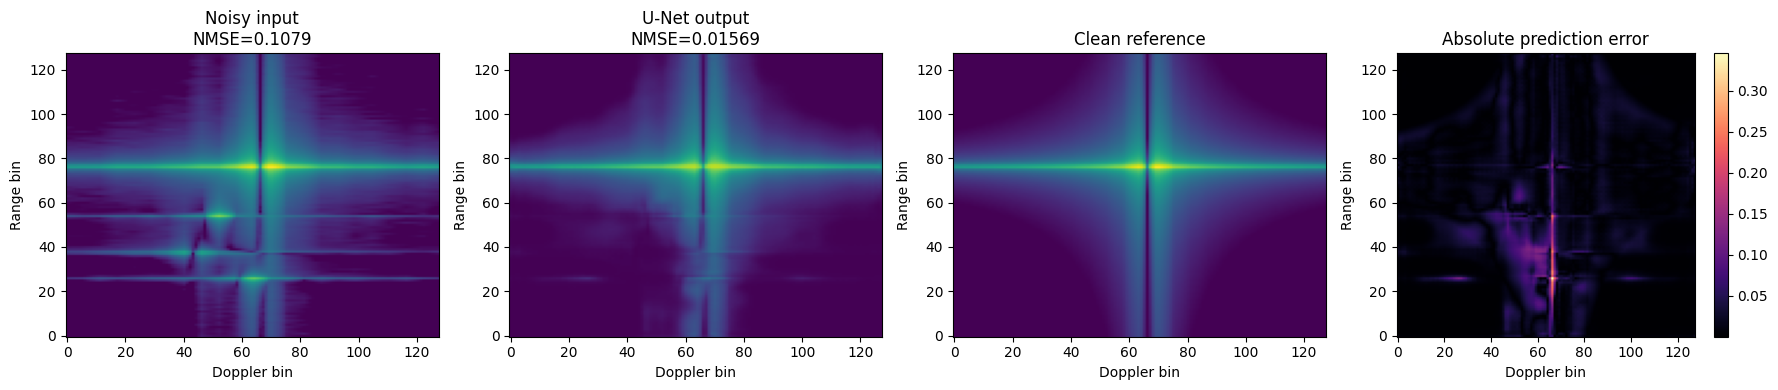

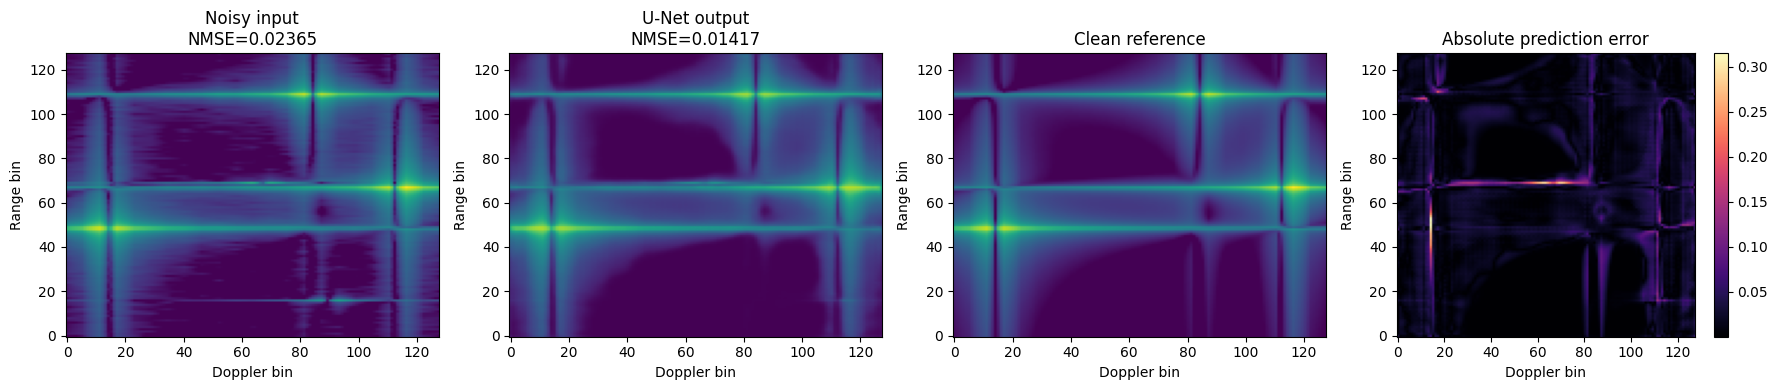

In [11]:
def visualize_test_sample(index=0):
    noisy = noisy_test[index, 0]
    predicted = np.clip(pred_test[index, 0], 0, 1)
    clean = clean_test[index, 0]

    error = np.abs(predicted - clean)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))

    axes[0].imshow(
        noisy, origin="lower", aspect="auto",
        vmin=0, vmax=1
    )
    axes[0].set_title(
        f"Noisy input\nNMSE={nmse_noisy[index]:.4g}"
    )

    axes[1].imshow(
        predicted, origin="lower", aspect="auto",
        vmin=0, vmax=1
    )
    axes[1].set_title(
        f"U-Net output\nNMSE={nmse_unet[index]:.4g}"
    )

    axes[2].imshow(
        clean, origin="lower", aspect="auto",
        vmin=0, vmax=1
    )
    axes[2].set_title("Clean reference")

    im = axes[3].imshow(
        error, origin="lower", aspect="auto",
        cmap="magma"
    )
    axes[3].set_title("Absolute prediction error")

    for ax in axes:
        ax.set_xlabel("Doppler bin")
        ax.set_ylabel("Range bin")

    fig.colorbar(im, ax=axes[3])
    plt.tight_layout()
    plt.show()


visualize_test_sample(0)

if len(noisy_test) > 1:
    visualize_test_sample(1)